# Notebook 7 – Outlier Analysis
## Goal
Detect unusual observations, investigate why they occur, and make a justified decision about whether to retain, correct, transform, or remove them.

**Core rule: Do not automatically remove every outlier.** An unusual value may be a data error, a rare but valid event, or the most important observation in the dataset.

## 1. What is an Outlier?
**Definition:** An outlier is an observation that differs substantially from the general pattern of the data. Whether a point is an outlier depends on the variable, context, and method used.

**Simple example:** In values `[10, 11, 12, 13, 100]`, 100 is much larger than the others.

**Real-world example:** A sensor may record an unusually high temperature because of a fault—or because a real heat event occurred.

**Business example:** One order may be much larger than a shop's typical order.

**AI/ML use case:** Outliers can distort scaling, means, regression, clustering, and anomaly-detection models.

**Why it matters:** Outlier analysis protects data quality while preserving rare but meaningful events.

## 2. Why Outliers Occur
Common causes:
- Data-entry or unit-conversion errors.
- Faulty sensors or broken data pipelines.
- Sampling from a different population.
- Rare but genuine events.
- Skewed distributions where extreme values are expected.
- Fraud or unusual behavior that deserves investigation.

**Simple example:** Typing `1000` instead of `100` may create an error.

**Real-world example:** A faulty temperature sensor can report an impossible value.

**Business example:** A customer may make a genuine bulk purchase, or an order amount may contain an extra zero.

**AI/ML use case:** Fraud detection often focuses on rare observations; removing all extremes could remove the events the model needs to learn.

**Why it matters:** The cause determines the appropriate treatment. A statistical flag alone cannot tell you why a value is unusual.

## 3. Types of Outliers
- **Univariate outlier:** unusual in one variable considered by itself.
- **Multivariate outlier:** unusual combination of values across several variables, even if each value is individually ordinary.
- **Global outlier:** unusual compared with the overall dataset.
- **Contextual outlier:** unusual only in a particular context, such as a high temperature for that season.
- **Collective outlier:** a group or sequence is unusual together, such as a sudden burst of network traffic.

**Simple example:** A person's height may be unusual by itself (univariate), while a normal height paired with an implausible weight/height combination may be multivariate.

**Real-world example:** A network request volume may be normal overall but abnormal at 3 a.m. (contextual).

**Business example:** A sale price may be normal during a clearance event but unusual on an ordinary day.

**AI/ML use case:** Multivariate anomaly detection can find suspicious combinations of transaction amount, time, and location.

**Why it matters:** One method cannot detect every kind of outlier.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
sales = pd.DataFrame({
    "Order_ID": range(1, 13),
    "Order_Value": [100, 120, 110, 130, 125, 115, 140, 105, 135, 128, 122, 950],
    "Items": [2, 3, 2, 4, 3, 2, 4, 2, 3, 3, 2, 25]
})
sales

,Order_ID,Order_Value,Items
0,1,100,2
1,2,120,3
2,3,110,2
3,4,130,4
4,5,125,3
5,6,115,2
6,7,140,4
7,8,105,2
8,9,135,3
9,10,128,3


## 4. Univariate Outliers
**Definition:** A univariate method looks at one variable at a time. The IQR and Z-score methods are common approaches for numerical data.

The methods flag unusual values; they do not determine whether those values are errors.

## 5. IQR Method
**Definition:** The interquartile range is `Q3 - Q1`. A common rule flags values below `Q1 - 1.5 × IQR` or above `Q3 + 1.5 × IQR`.

**Formula**
- `IQR = Q3 - Q1`
- Lower bound = `Q1 - 1.5 * IQR`
- Upper bound = `Q3 + 1.5 * IQR`

In [2]:
q1 = sales["Order_Value"].quantile(0.25)
q3 = sales["Order_Value"].quantile(0.75)
iqr = q3 - q1
lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr

outlier_mask_iqr = (
    (sales["Order_Value"] < lower_bound) |
    (sales["Order_Value"] > upper_bound)
)

print("Q1:", q1)
print("Q3:", q3)
print("IQR:", iqr)
print("Lower bound:", lower_bound)
print("Upper bound:", upper_bound)
print("Flagged rows:")
sales[outlier_mask_iqr]

Q1: 113.75
Q3: 131.25
IQR: 17.5
Lower bound: 87.5
Upper bound: 157.5
Flagged rows:


,Order_ID,Order_Value,Items
11,12,950,25


**Simple example:** If most order values fall around 100–140, a value of 950 may be flagged by the IQR rule.

**Real-world example:** IQR can flag unusually high measurements in a dataset without assuming a normal distribution.

**Business example:** It can identify unusually large order amounts for manual review.

**AI/ML use case:** IQR is often used during exploratory data analysis to flag potentially extreme numeric features.

**Why it matters:** It is easy to explain and is less sensitive to extreme values than rules based on the mean and standard deviation. Its flags still need context.

## 6. Z-Score Method
**Definition:** A Z-score describes how many standard deviations a value is from the mean. A common screening rule flags absolute Z-scores greater than 3, but this is only a heuristic and works best when the distribution is reasonably well-behaved.

`z = (value - mean) / standard deviation`

In [3]:
mean_value = sales["Order_Value"].mean()
std_value = sales["Order_Value"].std(ddof=0)
sales["Z_Score"] = (sales["Order_Value"] - mean_value) / std_value
sales["Flag_Z_Score"] = sales["Z_Score"].abs() > 3
sales[["Order_ID", "Order_Value", "Z_Score", "Flag_Z_Score"]]

,Order_ID,Order_Value,Z_Score,Flag_Z_Score
0,1,100,-0.392273,False
1,2,120,-0.305101,False
2,3,110,-0.348687,False
3,4,130,-0.261516,False
4,5,125,-0.283308,False
5,6,115,-0.326894,False
6,7,140,-0.217930,False
7,8,105,-0.370480,False
8,9,135,-0.239723,False
9,10,128,-0.270233,False


**Simple example:** A value far above the mean relative to the standard deviation gets a large positive Z-score.

**Real-world example:** A lab may screen measurements that are several standard deviations from the expected value, then verify them.

**Business example:** An analyst may review an unusually high daily transaction amount.

**AI/ML use case:** Standardized scores can help screen features for extreme values before some modeling methods.

**Why it matters:** Z-scores put distances on a common scale. **Caution:** the mean and standard deviation themselves can be distorted by extreme values, and skewed data may be flagged poorly.

## 7. Box Plot
**Definition:** A box plot displays the median, quartiles, and potential points beyond the whiskers. With the common 1.5-IQR whisker rule, points outside the whiskers are flagged as potential outliers—not automatically errors.

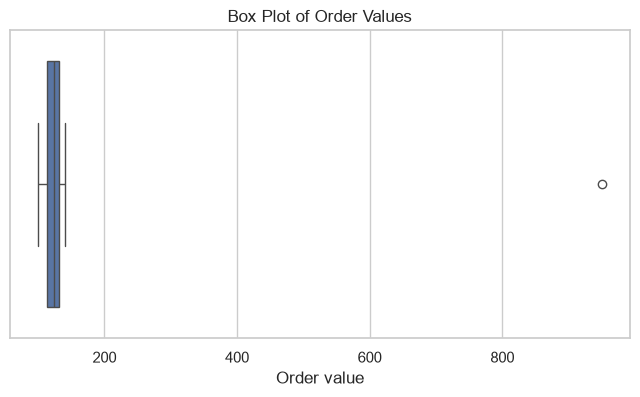

In [4]:
plt.figure(figsize=(8, 4))
sns.boxplot(x=sales["Order_Value"])
plt.title("Box Plot of Order Values")
plt.xlabel("Order value")
plt.show()

**Simple example:** The point at 950 should stand out from the typical order values.

**Real-world example:** Box plots can compare measurements across hospitals or regions.

**Business example:** Compare order values across product categories to see whether extreme orders occur in one category.

**AI/ML use case:** Box plots are a quick visual screen during EDA.

**Why it matters:** They summarize the distribution and show possible extremes in a compact chart.

## 8. Scatter Plot
**Definition:** A scatter plot displays two numerical variables. It can reveal points that are unusual in one variable or unusual relative to the relationship between the variables.

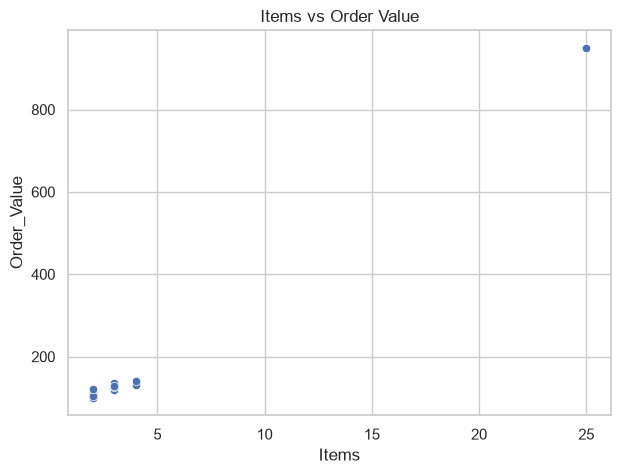

In [5]:
plt.figure(figsize=(7, 5))
sns.scatterplot(data=sales, x="Items", y="Order_Value")
plt.title("Items vs Order Value")
plt.show()

**Simple example:** An order with 25 items and value 950 is far from the other orders in this sample.

**Real-world example:** Plot engine temperature against engine speed to find unusual combinations.

**Business example:** Plot units ordered against total order value; an unusually large order may be valid or may require checking.

**AI/ML use case:** Scatter plots help inspect two-feature anomalies before using more formal multivariate methods.

**Why it matters:** A point can be unusual because of its relationship to another variable, not just because one value is large.

## 9. Multivariate Outliers
**Definition:** A multivariate outlier is an observation that is unusual when several features are considered together. It may not be extreme on any single feature.

One possible technique is the Mahalanobis distance, which accounts for the covariance between features. It requires careful assumptions and enough suitable data; for this beginner notebook, start by visualizing two features.

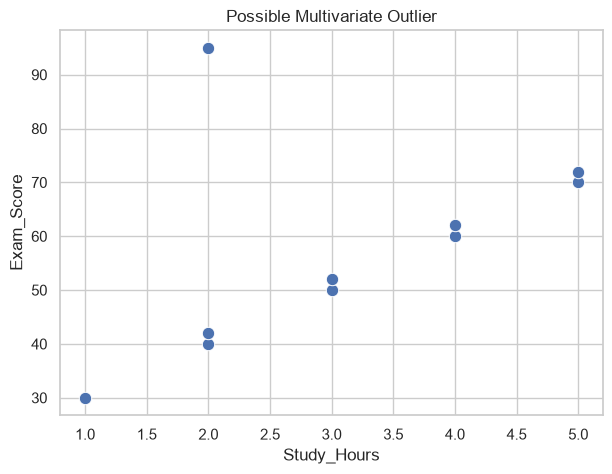

In [6]:
# Illustrative example: each value alone may look ordinary,
# but the combination can be unusual compared with the general pattern.
points = pd.DataFrame({
    "Study_Hours": [1, 2, 2, 3, 3, 4, 4, 5, 5, 2],
    "Exam_Score":  [30, 40, 42, 50, 52, 60, 62, 70, 72, 95]
})
plt.figure(figsize=(7, 5))
sns.scatterplot(data=points, x="Study_Hours", y="Exam_Score", s=80)
plt.title("Possible Multivariate Outlier")
plt.show()

**Simple example:** A student with ordinary study hours but an unusually high score relative to the observed pattern may merit checking—not assuming it is wrong.

**Real-world example:** A machine's temperature and vibration may each be individually acceptable, while their combination indicates a fault.

**Business example:** A transaction amount may be typical, and the location may be common, but the combination of amount, location, time, and account history may be suspicious.

**AI/ML use case:** Multivariate anomaly detection can identify unusual feature combinations in fraud, cybersecurity, and equipment monitoring.

**Why it matters:** Real anomalies often appear in relationships between variables rather than in a single column.

## 10. Decide What to Do With Detected Outliers
For every flagged observation, ask:
1. **Is it a genuine observation?** Check source records, domain limits, and other evidence.
2. **Is it a data-entry or processing error?** Verify the original record and units.
3. **Is it unusual but valid?** For example, a genuine bulk order.
4. **Should it be removed?** Only with a defensible reason, such as a confirmed invalid record or a stated analysis rule.
5. **Should it be transformed?** A log transform may help with a strongly right-skewed positive variable, but interpretability changes.
6. **Should it be retained?** Retain valid values when they represent the population you want to analyze.
7. **Should it be handled separately?** Consider robust statistics, segmentation, winsorization with documented limits, or an anomaly flag.

Never choose a treatment only because it improves a chart or model score.

In [7]:
# Create a transparent review table instead of deleting rows automatically.
review = sales[["Order_ID", "Order_Value", "Items"]].copy()
review["Flagged_by_IQR"] = outlier_mask_iqr
review["Initial_review_question"] = np.where(
    review["Flagged_by_IQR"],
    "Verify source record and business context",
    "No IQR flag; still check data quality"
)
review

,Order_ID,Order_Value,Items,Flagged_by_IQR,Initial_review_question
0,1,100,2,False,No IQR flag; still check data quality
1,2,120,3,False,No IQR flag; still check data quality
2,3,110,2,False,No IQR flag; still check data quality
3,4,130,4,False,No IQR flag; still check data quality
4,5,125,3,False,No IQR flag; still check data quality
5,6,115,2,False,No IQR flag; still check data quality
6,7,140,4,False,No IQR flag; still check data quality
7,8,105,2,False,No IQR flag; still check data quality
8,9,135,3,False,No IQR flag; still check data quality
9,10,128,3,False,No IQR flag; still check data quality


### Worked decision example
The row with order value 950 and 25 items is flagged as unusual. We do **not** have enough evidence to call it an error.

- If the original invoice confirms a legitimate bulk order, retain it.
- If the invoice says 95 and the dataset says 950, correct the value from the source record and document the correction.
- If it is valid but highly skewed, consider a log transformation for an appropriate model, or use robust methods.
- If the task is specifically to model typical small orders, analyze large orders separately—but explain the scope decision.

**Documentation example:** “Order 12 was flagged by the IQR rule. The source invoice was checked. The order was confirmed as a valid bulk purchase, so it was retained.”

## 11. Outlier Treatment Choices
| Choice | When it may be appropriate | Main caution |
|---|---|---|
| Retain | Value is valid and relevant | May influence mean-based methods |
| Correct | Source confirms a recording error | Never guess the corrected value |
| Remove | Record is invalid or outside a justified study scope | Can bias results if valid extremes are removed |
| Transform | Skewed values are valid and model assumptions benefit | Changes scale and interpretation |
| Cap / winsorize | A justified robust-analysis plan calls for limiting influence | Choose limits transparently; extremes lose detail |
| Analyze separately | Rare events represent a distinct segment | Report both overall and segment findings when relevant |

## 12. Mini Practice
1. Calculate IQR bounds for `Order_Value`.
2. Which rows are flagged by IQR?
3. Why might a Z-score be unreliable for highly skewed data?
4. Give one example of a valid business outlier.
5. What evidence would you collect before removing a flagged order?
6. Explain the difference between univariate and multivariate outliers.
7. Write one sentence documenting a retain/correct/remove decision.